In [2]:
import pandas as pd

# Carregar o ficheiro CSV para um DataFrame
df = pd.read_csv("Datasets/Social_media_impact_on_life.csv")


In [3]:
# Visualizar as 5 primeiras linhas do DataFrame
display(df.head())

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [4]:
# Obter iinformações técnicas gerais
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [5]:
# Mostra as estatísticas descritivas do DataFrame
display(df.describe())

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


In [6]:
# Calcular a médias das colunas em que há valores nulos
media_stress = df['Perceived_Stress_Score'].mean()
media_gpa = df['Academic_Performance_GPA'].mean()

# Preencher os valores nulos com a média das colunas
df['Perceived_Stress_Score'] = df['Perceived_Stress_Score'].fillna(media_stress)
df['Academic_Performance_GPA'] = df['Academic_Performance_GPA'].fillna(media_gpa)

# Verificar se há valores nulos restantes
df.isnull().sum()

Student_ID                     0
Age                            0
Gender                         0
Academic_Level                 0
Primary_Platform               0
Daily_Usage_Hours              0
Weekend_Extra_Hours            0
Device_Type                    0
Sleep_Duration_Hours           0
Sleep_Quality_Score            0
Late_Night_Usage               0
Social_Comparison_Frequency    0
Perceived_Stress_Score         0
Mental_Health_Index            0
Academic_Performance_GPA       0
Overall_Impact                 0
dtype: int64

In [7]:
# Importando bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Correlação matemática (Horas de uso diárias vs Notas acadêmicas)

correlacao = df['Daily_Usage_Hours'].corr(df['Academic_Performance_GPA'])
print(f'A correlação entre as horas de uso diárias e as notas acadêmicas é: {correlacao:.2f}')


A correlação entre as horas de uso diárias e as notas acadêmicas é: -0.70


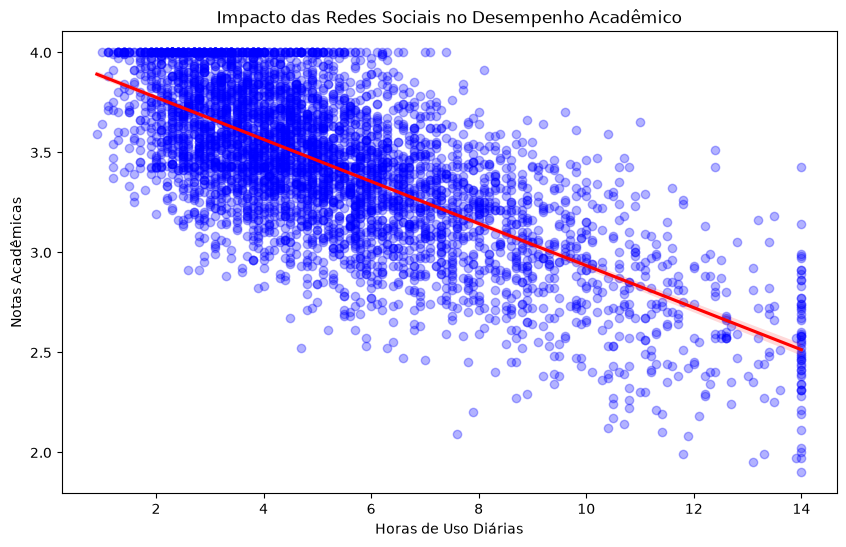

In [9]:
# Definir o tamanho da figura
plt.figure(figsize=(10,6))

# Gráfico de regressão. O Seaborn desenhar os pontos e a linha central de regressão
sns.regplot(
    x='Daily_Usage_Hours', 
    y='Academic_Performance_GPA',
    data=df,
    scatter_kws={'alpha': 0.3, 'color': 'blue'},
    line_kws={'color': 'red'}
)

# Títulos
plt.title('Impacto das Redes Sociais no Desempenho Acadêmico')
plt.xlabel('Horas de Uso Diárias')
plt.ylabel('Notas Acadêmicas')

# Exibir o gráfico
plt.show()

In [11]:
# Agrupamos as principais plataformas e depois calculamos apenas a média de stresse
stress_plataforma = df.groupby('Primary_Platform')['Perceived_Stress_Score'].mean().reset_index()

# Ordenamos de forma descrescente o nível de stresse percebido
stress_plataforma = stress_plataforma.sort_values(by='Perceived_Stress_Score', ascending=False)

# Mostrar resultados
display(stress_plataforma)



,Primary_Platform,Perceived_Stress_Score
1,LinkedIn,14.057418
3,Snapchat,13.968323
2,Reddit,13.672595
4,TikTok,13.590657
6,YouTube,13.458524
0,Instagram,13.413425
5,X (Twitter),12.475964


In [12]:
# Análise por gênero
analise_genero = df.groupby('Gender')[['Perceived_Stress_Score', 'Daily_Usage_Hours']].mean().reset_index()

analise_genero = analise_genero.round(2)

display(analise_genero)

,Gender,Perceived_Stress_Score,Daily_Usage_Hours
0,Female,13.39,5.32
1,Male,13.61,5.26
2,Non-Binary,14.36,5.40
3,Prefer not to say,13.13,5.36


In [17]:
# Análise do impacto do uso norturno nas horas de sono e na qualidade do sono
analise_sono = df.groupby('Late_Night_Usage')[['Sleep_Duration_Hours', 'Sleep_Quality_Score']].mean().reset_index()
display(analise_sono.round(2))

,Late_Night_Usage,Sleep_Duration_Hours,Sleep_Quality_Score
0,False,7.09,2.81
1,True,6.43,2.24


In [18]:
# Guardando nosso ficheiro limpo e tratado em um novo CSV
df.to_csv("Datasets/Social_media_impact_on_life_cleaned.csv", index=False)

print("Ficheiro limpo e tratado guardado com sucesso em 'Datasets/Social_media_impact_on_life_cleaned.csv'")

Ficheiro limpo e tratado guardado com sucesso em 'Datasets/Social_media_impact_on_life_cleaned.csv'
